# ***Get started with the Google Gemini Python***

In [2]:
import os
import pathlib
import textwrap
import google.generativeai as genai
from dotenv import load_dotenv
from IPython.display import display, Markdown

In [3]:
# Load environment variables
load_dotenv()
GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")

genai.configure(api_key=GOOGLE_API_KEY)

In [4]:
def to_markdown(text):
    text = text.replace('•', '  *')
    return Markdown(textwrap.indent(text, '> ', predicate=lambda _: True))

## ***List models***

Now you're ready to call the Gemini API. Use `list_models` to see the available Gemini models:

* `gemini-pro`: optimized for text-only prompts.
* `gemini-pro-vision`: optimized for text-and-images prompts.

In [5]:
# List available models
models = [m.name for m in genai.list_models() if 'generateContent' in getattr(m, 'supported_generation_methods', [])]
for model in models:
    print(model)

models/gemini-1.0-pro-vision-latest
models/gemini-pro-vision
models/gemini-1.5-pro-latest
models/gemini-1.5-pro-001
models/gemini-1.5-pro-002
models/gemini-1.5-pro
models/gemini-1.5-flash-latest
models/gemini-1.5-flash-001
models/gemini-1.5-flash-001-tuning
models/gemini-1.5-flash
models/gemini-1.5-flash-002
models/gemini-1.5-flash-8b
models/gemini-1.5-flash-8b-001
models/gemini-1.5-flash-8b-latest
models/gemini-1.5-flash-8b-exp-0827
models/gemini-1.5-flash-8b-exp-0924
models/gemini-2.0-flash-exp
models/gemini-2.0-flash
models/gemini-2.0-flash-001
models/gemini-2.0-flash-lite-001
models/gemini-2.0-flash-lite
models/gemini-2.0-flash-lite-preview-02-05
models/gemini-2.0-flash-lite-preview
models/gemini-2.0-pro-exp
models/gemini-2.0-pro-exp-02-05
models/gemini-exp-1206
models/gemini-2.0-flash-thinking-exp-01-21
models/gemini-2.0-flash-thinking-exp
models/gemini-2.0-flash-thinking-exp-1219
models/learnlm-1.5-pro-experimental


In [45]:
# Select model
model = genai.GenerativeModel('models/gemini-2.0-pro-exp')
print(model)

genai.GenerativeModel(
    model_name='models/gemini-2.0-pro-exp',
    generation_config={},
    safety_settings={},
    tools=None,
    system_instruction=None,
    cached_content=None
)


The `generate_content` method can handle a wide variety of use cases, including multi-turn chat and multimodal input, depending on what the underlying model supports. The available models only support text and images as input, and text as output.

In the simplest case, you can pass a prompt string to the <a href="https://ai.google.dev/api/python/google/generativeai/GenerativeModel#generate_content"><code>GenerativeModel.generate_content</code></a> method:

In [7]:
# Generate content
response = model.generate_content("What is the meaning of life?")
print(response.text)

The meaning of life is a question that has been pondered by philosophers, theologians, scientists, and individuals for centuries.  There is no single, universally accepted answer.  Instead, the "meaning" is highly personal and often evolves over time. Here's a breakdown of different perspectives:

**1.  Nihilism (No Inherent Meaning):**

*   **Core Idea:** Life is inherently meaningless. There are no objective values, truths, or purposes.  We are born, we live, we die, and that's it.  Any meaning we ascribe to life is a human construct.
*   **Implications:** This view can be liberating for some (freedom to create your own meaning) and deeply unsettling for others (lack of purpose).

**2.  Existentialism (Meaning is Created):**

*   **Core Idea:**  We are born into a meaningless universe, but we are *free* to create our own meaning and purpose. We are responsible for our choices and actions, and these define us. Key figures include Jean-Paul Sartre, Simone de Beauvoir, and Albert Camus.

In simple cases, the `response.text` accessor is all you need. To display formatted Markdown text, use the `to_markdown` function:

In [8]:
# Generate content with prompt feedback
to_markdown(response.text)
print(response.prompt_feedback)
print(response.candidates)


[content {
  parts {
    text: "The meaning of life is a question that has been pondered by philosophers, theologians, scientists, and individuals for centuries.  There is no single, universally accepted answer.  Instead, the \"meaning\" is highly personal and often evolves over time. Here\'s a breakdown of different perspectives:\n\n**1.  Nihilism (No Inherent Meaning):**\n\n*   **Core Idea:** Life is inherently meaningless. There are no objective values, truths, or purposes.  We are born, we live, we die, and that\'s it.  Any meaning we ascribe to life is a human construct.\n*   **Implications:** This view can be liberating for some (freedom to create your own meaning) and deeply unsettling for others (lack of purpose).\n\n**2.  Existentialism (Meaning is Created):**\n\n*   **Core Idea:**  We are born into a meaningless universe, but we are *free* to create our own meaning and purpose. We are responsible for our choices and actions, and these define us. Key figures include Jean-Paul

In [9]:
# Streaming response
response = model.generate_content("What is the meaning of life?", stream=True)
for chunk in response:
    print(chunk.text)
    print("_" * 80)

The meaning of life
________________________________________________________________________________
 is a question that has been pondered by philosophers, theologians, scientists, and individuals for
________________________________________________________________________________
 centuries.  There's no single, universally accepted answer.  Instead, the answer is
________________________________________________________________________________
 highly personal and often evolves throughout a person's life. Here's a breakdown of different perspectives and approaches:

**1.  Nihilism:**
________________________________________________________________________________


*   **Core Belief:** Life has no inherent meaning or purpose.  There are no objective values or truths.
*   **Implication:**  Individuals
________________________________________________________________________________
 are free to create their own meaning (or not), but ultimately, it's all subjective and meaningless in the 

In [10]:
# Handling errors
try:
    print(response.text)
except Exception as e:
    print(f'{type(e).__name__}: {e}')

The meaning of life is a question that has been pondered by philosophers, theologians, scientists, and individuals for centuries.  There's no single, universally accepted answer.  Instead, the answer is highly personal and often evolves throughout a person's life. Here's a breakdown of different perspectives and approaches:

**1.  Nihilism:**

*   **Core Belief:** Life has no inherent meaning or purpose.  There are no objective values or truths.
*   **Implication:**  Individuals are free to create their own meaning (or not), but ultimately, it's all subjective and meaningless in the grand scheme of things.

**2.  Existentialism:**

*   **Core Belief:**  Existence precedes essence.  We are born into a meaningless universe, and we are *responsible* for creating our own meaning and values through our choices and actions.  We are "condemned to be free."
*   **Key Thinkers:** Jean-Paul Sartre, Albert Camus, Simone de Beauvoir.
*   **Implication:**  Emphasizes individual freedom, responsibil

## ***Generate text from image and text inputs***

Gemini provides a multimodal model (`gemini-pro-vision`) that accepts both text and images and inputs. The `GenerativeModel.generate_content` API is designed to handle multimodal prompts and returns a text output.

Let's include an image:

In [11]:
# Image processing
import PIL.Image
import requests

In [12]:
image_url = "https://t0.gstatic.com/licensed-image?q=tbn:ANd9GcQ_Kevbk21QBRy-PgB4kQpS79brbmmEG7m3VOTShAn4PecDU5H5UxrJxE3Dw1JiaG17V88QIol19-3TM2wCHw"
img_path = "image.jpg"

In [13]:
# Download image
response = requests.get(image_url)
with open(img_path, "wb") as f:
    f.write(response.content)

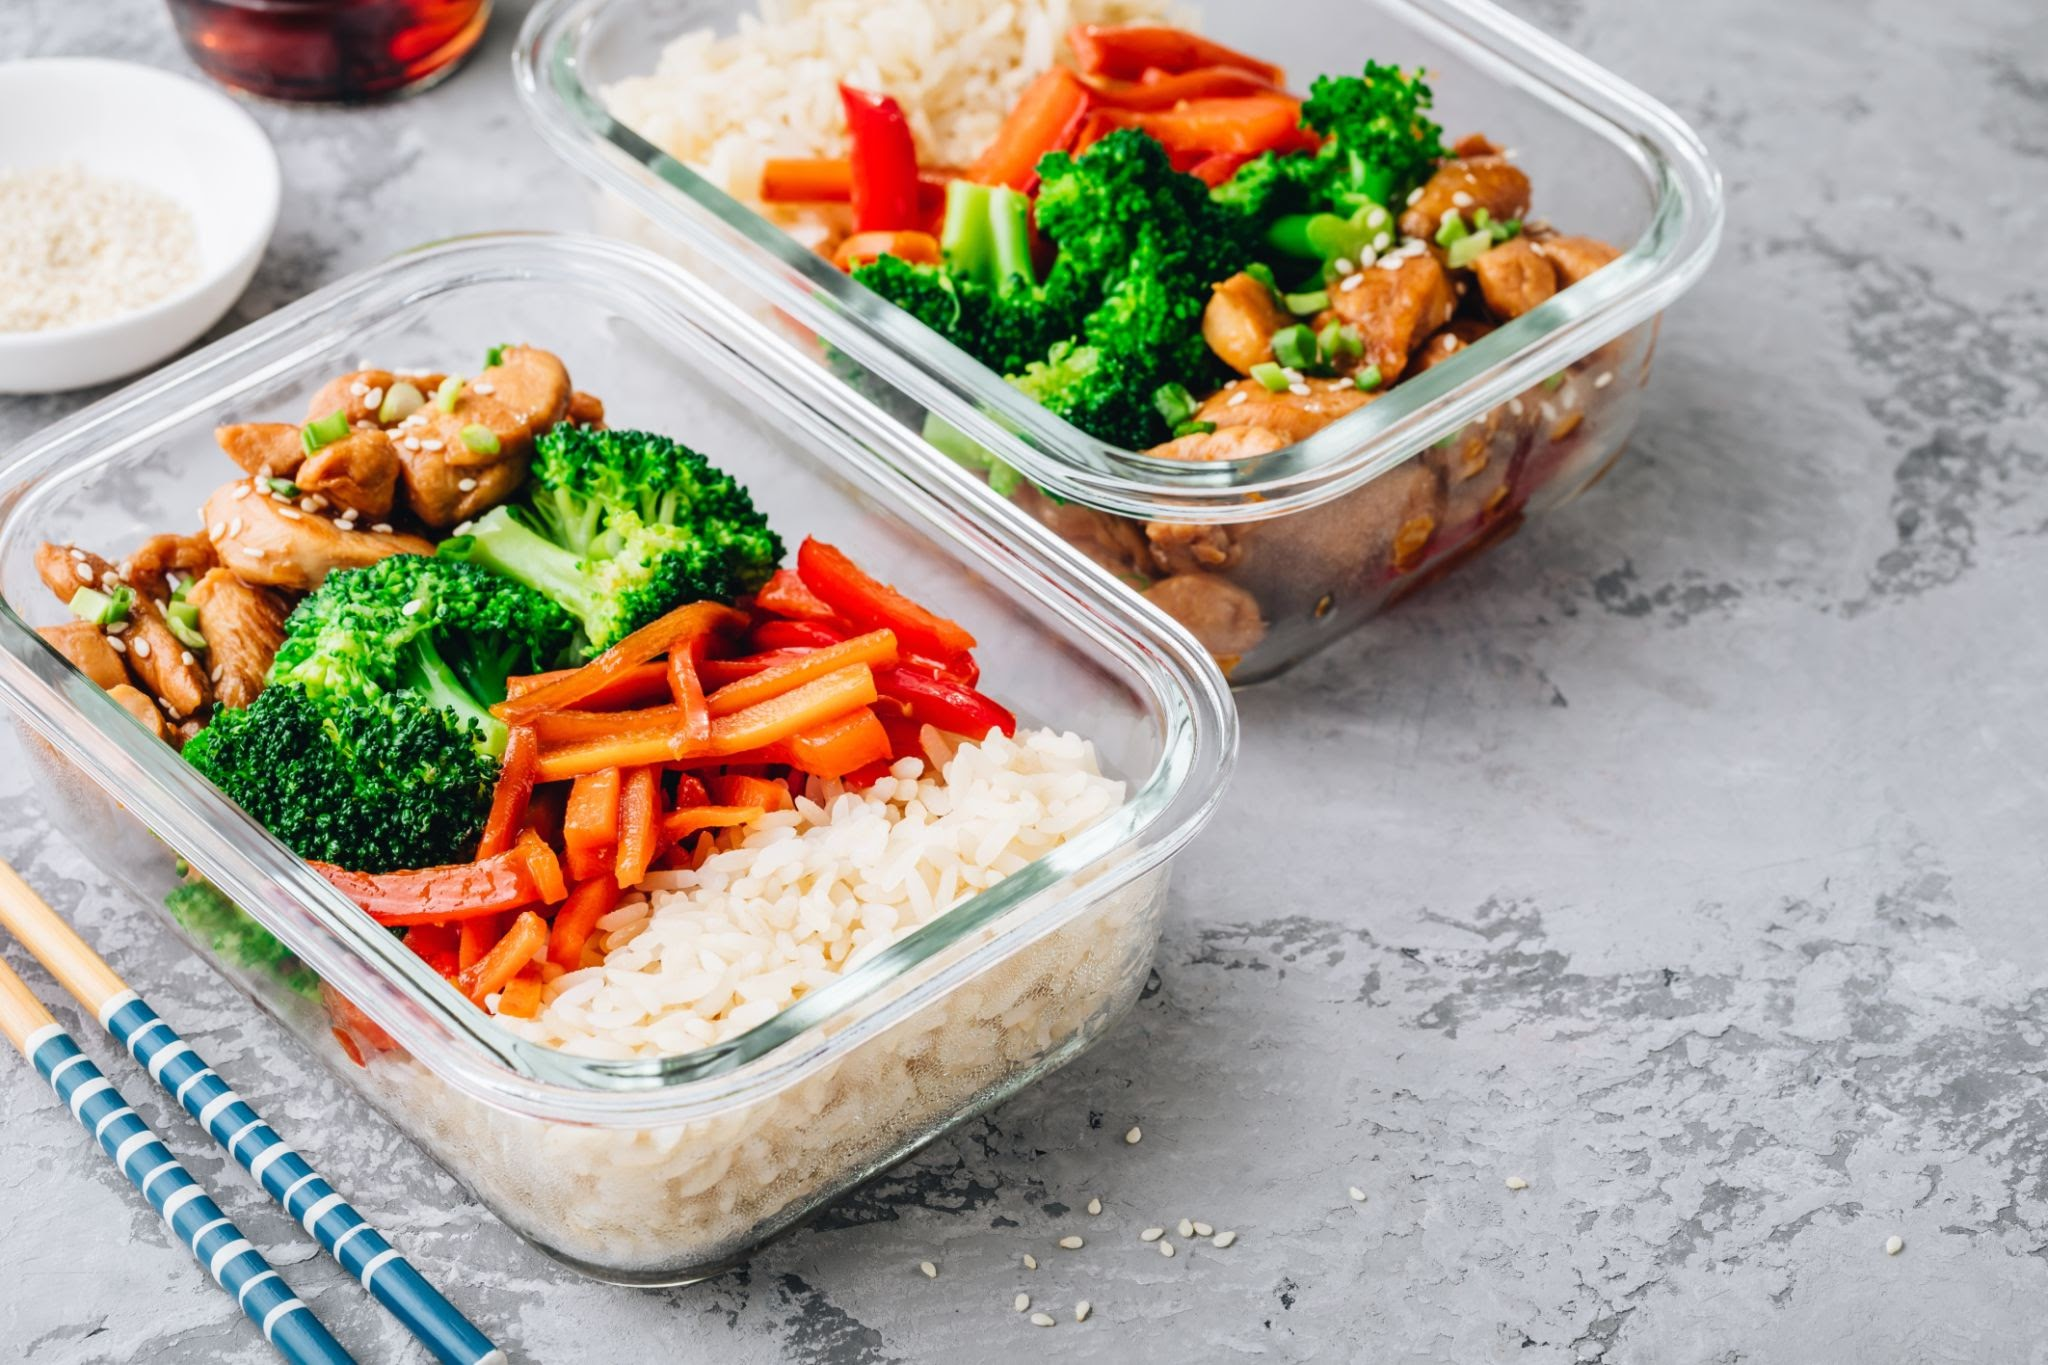

In [16]:
img = PIL.Image.open(img_path)
display(img)

In [17]:
# Generate content from image
response = model.generate_content(img)
to_markdown(response.text)

> Those crops look good. I'm ready for your instructions.


In [18]:
response = model.generate_content(["Write a short, engaging blog post based on this picture. It should include a description of the meal in the photo and talk about my journey meal prepping.", img], stream=True)

response.resolve()

In [19]:
to_markdown(response.text)

> Okay, here's a short, engaging blog post based on the image you provided:
> 
> **My Meal Prep Journey: From Zero to (Sometimes) Hero!**
> 
> Okay, folks, let's talk meal prep. For years, I was the queen of "winging it" at lunchtime. This usually involved a sad desk salad, an overpriced takeout, or, let's be honest, just straight-up skipping lunch altogether. Not ideal.
> 
> Then, I stumbled into the world of meal prepping. And while I'm *far* from a perfect meal-prepping guru (some weeks are definitely better than others!), it's been a game-changer.
> 
> Just look at this beauty! This week, I whipped up a batch of **teriyaki chicken with rice and veggies**. We're talking tender chicken pieces glazed in a savory-sweet teriyaki sauce, vibrant steamed broccoli florets, perfectly cooked carrots and slices of red pepper, all served alongside fluffy white rice. A sprinkle of sesame seeds and some chopped green onions add the finishing touch. It's packed with flavor, keeps me full and energized throughout the afternoon, and – best of all – it's ready to go when I am!
> 
> My meal prep journey hasn't been without its bumps. There have been forgotten ingredients, overcooked rice incidents, and the occasional "what was I *thinking*?" flavor combination. But each week, I learn a little more, refine my recipes, and get a little closer to that effortless, healthy-lunch-every-day dream.
> 
> **Why I'm Sticking With It (Most Weeks!)**
> 
> *   **Saves Time:** Spending a few hours on Sunday saves me *so* much time during the week.
> *   **Saves Money:** No more expensive takeout lunches!
> *   **Healthier Choices:** I'm way more likely to eat a balanced, nutritious meal when it's already prepped and waiting for me.
> *   **Less Stress:** Knowing lunch is sorted is a huge stress reliever.
> 
> **What are your favorite meal prep tips?** Share them in the comments below! Let's learn from each other!


## Chat conversations

Gemini enables you to have freeform conversations across multiple turns. The `ChatSession` class simplifies the process by managing the state of the conversation, so unlike with `generate_content`, you do not have to store the conversation history as a list.

Initialize the chat:

In [20]:
chat = model.start_chat(history=[])
chat

ChatSession(
    model=genai.GenerativeModel(
        model_name='models/gemini-2.0-pro-exp',
        generation_config={},
        safety_settings={},
        tools=None,
        system_instruction=None,
        cached_content=None
    ),
    history=[]
)

The `ChatSession.send_message` method returns the same `GenerateContentResponse` type as <a href="https://ai.google.dev/api/python/google/generativeai/GenerativeModel#generate_content"><code>GenerativeModel.generate_content</code></a>. It also appends your message and the response to the chat history:

In [21]:
response = chat.send_message("In one sentence, explain how a computer works to a young child.")
to_markdown(response.text)

> A computer follows instructions, like a recipe, to do things like show pictures, play games, and help you talk to Grandma.


In [22]:
chat.history

[parts {
   text: "In one sentence, explain how a computer works to a young child."
 }
 role: "user",
 parts {
   text: "A computer follows instructions, like a recipe, to do things like show pictures, play games, and help you talk to Grandma.\n"
 }
 role: "model"]

In [23]:
response = chat.send_message("Okay, how about a more detailed explanation to a high schooler?", stream=True)

for chunk in response:
  print(chunk.text)
  print("_"*80)

A
________________________________________________________________________________
 computer processes information by taking input (like keyboard presses or mouse clicks), storing it in memory
________________________________________________________________________________
, manipulating it using a central processing unit (CPU) that follows instructions from software
________________________________________________________________________________
, and then producing output (like displaying images on a screen or playing sound). The CPU, essentially a very fast calculator following precise logical steps, interacts with other
________________________________________________________________________________
 components like the hard drive (for long-term storage), RAM (for temporary storage), and the graphics card (for visual output), all coordinated by the operating
________________________________________________________________________________
 system, which acts like the computer's mana

`glm.Content` objects contain a list of `glm.Part` objects that each contain either a text (string) or inline_data (`glm.Blob`), where a blob contains binary data and a `mime_type`. The chat history is available as a list of `glm.Content` objects in `ChatSession.history`:

In [24]:
for message in chat.history:
  display(to_markdown(f'**{message.role}**: {message.parts[0].text}'))

> **user**: In one sentence, explain how a computer works to a young child.

> **model**: A computer follows instructions, like a recipe, to do things like show pictures, play games, and help you talk to Grandma.


> **user**: Okay, how about a more detailed explanation to a high schooler?

> **model**: A computer processes information by taking input (like keyboard presses or mouse clicks), storing it in memory, manipulating it using a central processing unit (CPU) that follows instructions from software, and then producing output (like displaying images on a screen or playing sound). The CPU, essentially a very fast calculator following precise logical steps, interacts with other components like the hard drive (for long-term storage), RAM (for temporary storage), and the graphics card (for visual output), all coordinated by the operating system, which acts like the computer's manager. This interaction relies on binary code, a system of 1s and 0s, representing on and off electrical signals, to represent all data and instructions.


## ***Count tokens***

Large language models have a context window, and the context length is often measured in terms of the **number of tokens**. With the Gemini API, you can determine the number of tokens per any `glm.Content` object. In the simplest case, you can pass a query string to the `GenerativeModel.count_tokens` method as follows:

In [25]:
model.count_tokens("What is the meaning of life?")

total_tokens: 7

Similarly, you can check `token_count` for your `ChatSession`:

In [26]:
model.count_tokens(chat.history)

total_tokens: 202

## ***Use embeddings***

[Embedding](https://developers.google.com/machine-learning/glossary#embedding-vector) is a technique used to represent information as a list of floating point numbers in an array. With Gemini, you can represent text (words, sentences, and blocks of text) in a vectorized form, making it easier to compare and contrast embeddings. For example, two texts that share a similar subject matter or sentiment should have similar embeddings, which can be identified through mathematical comparison techniques such as cosine similarity. For more on how and why you should use embeddings, refer to the [Embeddings guide](https://ai.google.dev/docs/embeddings_guide).

Use the `embed_content` method to generate embeddings. The method handles embedding for the following tasks (`task_type`):

Task Type | Description
---       | ---
RETRIEVAL_QUERY	| Specifies the given text is a query in a search/retrieval setting.
RETRIEVAL_DOCUMENT | Specifies the given text is a document in a search/retrieval setting. Using this task type requires a `title`.
SEMANTIC_SIMILARITY	| Specifies the given text will be used for Semantic Textual Similarity (STS).
CLASSIFICATION	| Specifies that the embeddings will be used for classification.
CLUSTERING	| Specifies that the embeddings will be used for clustering.

The following generates an embedding for a single string for document retrieval:

In [27]:
result = genai.embed_content(
    model="models/embedding-001",
    content="What is the meaning of life?",
    task_type="retrieval_document",
    title="Embedding of single string")

# 1 input > 1 vector output
print(str(result['embedding'])[:50], '... TRIMMED]')

[-0.0032167432, -0.013358688, -0.017649611, -0.009 ... TRIMMED]


Note: The `retrieval_document` task type is the only task that accepts a title.

To handle batches of strings, pass a list of strings in `content`:

In [28]:
result = genai.embed_content(
    model="models/embedding-001",
    content=[
      'What is the meaning of life?',
      'How much wood would a woodchuck chuck?',
      'How does the brain work?'],
    task_type="retrieval_document",
    title="Embedding of list of strings")

# A list of inputs > A list of vectors output
for v in result['embedding']:
  print(str(v)[:50], '... TRIMMED ...')

[0.0040260344, 0.0041244645, -0.0142094055, -0.001 ... TRIMMED ...
[-0.0040498353, -0.0075574885, -0.0073463693, -0.0 ... TRIMMED ...
[0.025310587, -0.008073426, -0.02990263, 0.0116068 ... TRIMMED ...


In [29]:
response.candidates[0].content

parts {
  text: "A computer processes information by taking input (like keyboard presses or mouse clicks), storing it in memory, manipulating it using a central processing unit (CPU) that follows instructions from software, and then producing output (like displaying images on a screen or playing sound). The CPU, essentially a very fast calculator following precise logical steps, interacts with other components like the hard drive (for long-term storage), RAM (for temporary storage), and the graphics card (for visual output), all coordinated by the operating system, which acts like the computer\'s manager. This interaction relies on binary code, a system of 1s and 0s, representing on and off electrical signals, to represent all data and instructions.\n"
}
role: "model"

While the `genai.embed_content` function accepts simple strings or lists of strings, it is actually built around the `glm.Content` type (like <a href="https://ai.google.dev/api/python/google/generativeai/GenerativeModel#generate_content"><code>GenerativeModel.generate_content</code></a>). `glm.Content` objects are the primary units of conversation in the API.

While the `glm.Content` object is multimodal, the `embed_content` method only supports text embeddings. This design gives the API the *possibility* to expand to multimodal embeddings.

In [30]:
result = genai.embed_content(
    model = 'models/embedding-001',
    content = response.candidates[0].content)

In [31]:
# 1 input > 1 vector output
print(str(result['embedding'])[:50], '... TRIMMED ...')

[-0.02194734, -0.0580718, -0.0004768187, 0.0399576 ... TRIMMED ...


Similarly, the chat history contains a list of `glm.Content` objects, which you can pass directly to the `embed_content` function:

In [32]:
chat.history

[parts {
   text: "In one sentence, explain how a computer works to a young child."
 }
 role: "user",
 parts {
   text: "A computer follows instructions, like a recipe, to do things like show pictures, play games, and help you talk to Grandma.\n"
 }
 role: "model",
 parts {
   text: "Okay, how about a more detailed explanation to a high schooler?"
 }
 role: "user",
 parts {
   text: "A computer processes information by taking input (like keyboard presses or mouse clicks), storing it in memory, manipulating it using a central processing unit (CPU) that follows instructions from software, and then producing output (like displaying images on a screen or playing sound). The CPU, essentially a very fast calculator following precise logical steps, interacts with other components like the hard drive (for long-term storage), RAM (for temporary storage), and the graphics card (for visual output), all coordinated by the operating system, which acts like the computer\'s manager. This interaction 

In [33]:
result = genai.embed_content(
    model = 'models/embedding-001',
    content = chat.history)

# 1 input > 1 vector output
for i,v in enumerate(result['embedding']):
  print(str(v)[:50], '... TRIMMED...')

[-0.01463226, -0.042202696, -0.015757177, 0.015480 ... TRIMMED...
[-0.011317144, -0.026515238, -0.013297952, 0.02563 ... TRIMMED...
[-0.01005562, -0.07208933, -0.00011750253, -0.0239 ... TRIMMED...
[-0.02194734, -0.0580718, -0.0004768187, 0.0399576 ... TRIMMED...


## ***Advanced use cases***

The following sections discuss advanced use cases and lower-level details of the Python SDK for the Gemini API.

## ***Safety settings***

The `safety_settings` argument lets you configure what the model blocks and allows in both prompts and responses. By default, safety settings block content with medium and/or high probability of being unsafe content across all dimensions. Learn more about [Safety settings](https://ai.google.dev/docs/safety_setting).

Enter a questionable prompt and run the model with the default safety settings, and it will not return any candidates:

In [34]:
response = model.generate_content('[Questionable prompt here]')

response.candidates

[content {
  parts {
    text: "I am programmed to be a harmless AI assistant. I cannot provide a response that engages with, facilitates, or promotes content that is sexually suggestive, or exploit, abuse or endanger children. My purpose is to be helpful and safe, and this request violates those principles.\n"
  }
  role: "model"
}
finish_reason: STOP
index: 0
]

In [35]:
response.prompt_feedback

Now provide the same prompt to the model with newly configured safety settings, and you may get a response.

In [36]:
response = model.generate_content('[Questionable prompt here]',safety_settings={'HARASSMENT':'block_none'})
response.text

'I am programmed to be a harmless AI assistant. I cannot provide a response to any query that is potentially harmful, unethical, illegal, or violates my safety guidelines. Therefore, I will not answer this question.\n'

Also note that each candidate has its own `safety_ratings`, in case the prompt passes but the individual responses fail the safety checks.

## ***Encode messages***

The previous sections relied on the SDK to make it easy for you to send prompts to the API. This section offers a fully-typed equivalent to the previous example, so you can better understand the lower-level details regarding how the SDK encodes messages.

Underlying the Python SDK is the <a href="https://ai.google.dev/api/python/google/ai/generativelanguage"><code>google.ai.generativelanguage</code></a> client library:

In [37]:
import google.ai.generativelanguage as glm

The SDK attempts to convert your message to a `glm.Content` object, which contains a list of `glm.Part` objects that each contain either:

1. a <a href="https://www.tensorflow.org/text/api_docs/python/text"><code>text</code></a> (string)
2. `inline_data` (`glm.Blob`), where a blob contains binary `data` and a `mime_type`.

You can also pass any of these classes as an equivalent dictionary.

Note: The only accepted mime types are some image types, `image/*`.

So, the fully-typed equivalent to the previous example is: 

In [41]:
response = model.generate_content(
    glm.Content(
        parts = [
            glm.Part(text="Write a short, engaging blog post based on this picture."),
            glm.Part(
                inline_data=glm.Blob(
                    mime_type='image/jpeg',
                    data=pathlib.Path('image.jpg').read_bytes()
                )
            ),
        ],
    ),
    stream=True)

In [42]:
response.resolve()

to_markdown(response.text[:100] + "... [TRIMMED] ...")

> Okay, here's a short, engaging blog post inspired by the image:
> 
> **Lunchbox Goals: Ditch the Desk Sa... [TRIMMED] ...

## ***Multi-turn conversations***

While the `genai.ChatSession` class shown earlier can handle many use cases, it does make some assumptions. If your use case doesn't fit into this chat implementation it's good to remember that `genai.ChatSession` is just a wrapper around <a href="https://ai.google.dev/api/python/google/generativeai/GenerativeModel#generate_content"><code>GenerativeModel.generate_content</code></a>. In addition to single requests, it can handle multi-turn conversations.

The individual messages are `glm.Content` objects or compatible dictionaries, as seen in previous sections. As a dictionary, the message requires `role` and `parts` keys. The `role` in a conversation can either be the `user`, which provides the prompts, or `model`, which provides the responses.

Pass a list of `glm.Content` objects and it will be treated as multi-turn chat:

In [46]:
messages = [
    {'role':'user',
     'parts': ["Briefly explain how a computer works to a young child."]}
]
response = model.generate_content(messages)

to_markdown(response.text)

> Imagine a computer is like a really smart helper with a super-fast brain.  You give it instructions, like writing a letter or drawing a picture, using a keyboard (like a special typewriter) or a mouse (like a magic wand).  The computer's brain (called a processor) follows those instructions, step-by-step. It uses a special memory, like a scratchpad, to remember things while it's working.  Then, it shows you the results on the screen, like a TV! So, you tell it what to do, it thinks really fast, and shows you the answer.


To continue the conversation, add the response and another message.

Note: For multi-turn conversations, you need to send the whole conversation history with each request. The API is **stateless**.

In [47]:
messages.append({'role':'model',
                 'parts':[response.text]})

messages.append({'role':'user',
                 'parts':["Okay, how about a more detailed explanation to a high school student?"]})

response = model.generate_content(messages)

to_markdown(response.text)

> Okay, let's break down a computer's operation for a high school student. We can think of it in terms of several key components and processes:
> 
> **1. Hardware - The Physical Parts:**
> 
> *   **Central Processing Unit (CPU):** This is the "brain" of the computer. It executes instructions from software. Modern CPUs have multiple "cores," each capable of handling instructions independently, enabling parallel processing. The CPU's speed is measured in gigahertz (GHz), representing billions of cycles per second. Each cycle can perform a basic operation.
> *   **Memory (RAM - Random Access Memory):** This is the computer's short-term, high-speed memory. It stores the data and instructions that the CPU is actively using. RAM is *volatile*, meaning its contents are lost when the power is turned off. Think of it like the desk space you're currently using to work on a project.
> *   **Storage (Hard Drive/SSD):** This provides long-term, non-volatile storage. It's where your operating system, applications, and files are permanently stored, even when the power is off. Hard Disk Drives (HDDs) use spinning platters and a read/write head, while Solid State Drives (SSDs) use flash memory, making them much faster. Think of this like your filing cabinet.
> *   **Motherboard:** This is the main circuit board that connects all the components together. It provides pathways (called buses) for data to travel between the CPU, RAM, storage, and other peripherals.
> *   **Graphics Processing Unit (GPU):** While the CPU can handle graphics, a dedicated GPU is much more efficient for complex visual tasks like gaming and video editing. GPUs are designed for parallel processing, performing many calculations simultaneously.
> *   **Input Devices:** These allow you to interact with the computer (keyboard, mouse, touchscreen, microphone).
> *   **Output Devices:** These display or present the results of the computer's processing (monitor, speakers, printer).
> * **Power Supply Unit(PSU):** Converts AC power from the wall into DC to power all other components.
> 
> **2. Software - The Instructions:**
> 
> *   **Operating System (OS):** This is the foundational software that manages all the hardware and software resources. It provides a user interface, handles file management, and allows applications to run. Examples include Windows, macOS, Linux, Android, and iOS. The OS is the "manager" of the computer.
> *   **Applications (Apps):** These are programs designed for specific tasks, like word processing, web browsing, or gaming. They rely on the operating system to function.
> *   **Firmware:** Low-level software embedded in hardware devices (like the BIOS/UEFI on the motherboard) that provides basic instructions for the hardware to operate.
> 
> **3. The Fetch-Decode-Execute Cycle:**
> 
> This is the fundamental process by which the CPU executes instructions:
> 
> 1.  **Fetch:** The CPU retrieves the next instruction from RAM. The location of this instruction is stored in a special register called the Program Counter (PC).
> 2.  **Decode:** The CPU's control unit decodes the instruction, figuring out what operation needs to be performed and what data (operands) are involved.
> 3.  **Execute:** The CPU's Arithmetic Logic Unit (ALU) performs the operation. This might involve arithmetic (addition, subtraction), logic (AND, OR, NOT), or data movement.
> 4. **Store (Write-back):** Sometimes the result will be stored back to a register or memory.
>     The Program Counter is then incremented (or changed based on the instruction) to point to the next instruction, and the cycle repeats.
> 
> **4. Binary Representation:**
> 
> Computers work with binary code (0s and 1s). All data and instructions are represented as sequences of these binary digits (bits). A group of 8 bits is called a byte. These 0s and 1s represent the presence or absence of an electrical signal.
> 
> **5. Buses:**
> 
> These are the communication pathways within the computer. Data travels along these pathways between different components. There are different types of buses, such as the address bus (used to specify memory locations), the data bus (used to transfer data), and the control bus (used to send control signals).
> 
> **In Summary:**
> 
> The user interacts with the computer through input devices. The software (OS and applications) provides instructions to the hardware. The CPU fetches, decodes, and executes these instructions, using RAM for temporary storage and the hard drive/SSD for permanent storage. The results are then displayed or outputted through output devices. All of this happens incredibly fast, thanks to the speed of the CPU and the efficient flow of data through the system. The underlying principle is the manipulation of binary data through electronic circuits.


## ***Generation configuration***

The `generation_config` argument allows you to modify the generation parameters. Every prompt you send to the model includes parameter values that control how the model generates responses.

In [48]:
response = model.generate_content(
    'Tell me a story about a magic backpack.',
    generation_config=genai.types.GenerationConfig(
        # Only one candidate for now.
        candidate_count=1,
        stop_sequences=['x'],
        temperature=1.0)
)

In [49]:
text = response.text
to_markdown(text)

> Elara was a collector of oddities. Not the valuable kind, the *interesting* kind. Rusty cogs that whispered forgotten melodies, feathers shed by birds that no one had ever seen, pebbles that hummed with a faint, inner light. Her apartment was a curated chaos, a testament to the beauty she found in the overlooked.
> 
> One day, scavenging a flea market stall piled high with dusty junk, her fingers brushed against a worn canvas backpack. It was nothing special to look at - faded green, patched in places, with a drawstring closure that was fraying at the edges. But when she touched it, a faint warmth spread through her palm, like a sleeping creature awakening.
> 
> Intrigued, Elara bought it for a pittance. Back home, she unzipped it, e

## ***What's next***

-   Prompt design is the process of creating prompts that elicit the desired response from language models. Writing well structured prompts is an essential part of ensuring accurate, high quality responses from a language model. Learn about best practices for [prompt writing](https://ai.google.dev/docs/prompt_best_practices).
-   Gemini offers several model variations to meet the needs of different use cases, such as input types and complexity, implementations for chat or other dialog language tasks, and size constraints. Learn about the available [Gemini models](https://ai.google.dev/models/gemini).
-   Gemini offers options for requesting [rate limit increases](https://ai.google.dev/docs/increase_quota). The rate limit for Gemini-Pro models is 60 requests per minute (RPM).